# Evaluación Parcial 2: Fundamentos de Inteligencia Artificial 🧠⚙️
**Tema:** Algoritmos Evolutivos, Algoritmos Genéticos, Ascenso de Colinas, Temple Simulado, ACO y PSO  
**Profesor:** Joaquín F. Sánchez  
**Curso:** Fundamentos de Inteligencia Artificial (2026)  
**Calificación Total:** 5,0 (Cinco puntos de 1,0 cada uno)

---

### 👥 Integrantes
* **Santiago Parra Acuña**
* **Sergio Morales**
* **Angel Robles**

---


In [1]:
# Configuración inicial del entorno y librerías
import math
import random
import numpy as np
import matplotlib.pyplot as plt

# Configuración estética global de gráficos
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 14,
    "figure.dpi": 300,
    "lines.linewidth": 1.8,
    "lines.markersize": 6,
    "grid.alpha": 0.35,
    "grid.linestyle": "--"
})


## Punto 1. Algoritmos Evolutivos y Algoritmos Genéticos (1,0)

Se desea maximizar la función:
$$f(x) = x^2, \quad x \in \{0, 1, \dots, 31\}$$

Cada solución se representa mediante un cromosoma binario de cinco bits.  
La población inicial dada es:
$$\mathcal{P} = \{00101, 01100, 10010, 11001\}$$

---

### A. Componente Matemático y Conceptual (0,5)

#### 1. Decodificación y Cálculo de Aptitud
Decodificamos cada cromosoma binario $(b_4 b_3 b_2 b_1 b_0)_2$ a su valor decimal $x = \sum_{k=0}^4 b_k 2^k$ y calculamos su aptitud $f(x) = x^2$:

* **Individuo 1:** $C_1 = 00101_2 = 0\cdot 16 + 0\cdot 8 + 1\cdot 4 + 0\cdot 2 + 1\cdot 1 = 5$  
  $$\text{Aptitud: } f(5) = 5^2 = 25$$
* **Individuo 2:** $C_2 = 01100_2 = 0\cdot 16 + 1\cdot 8 + 1\cdot 4 + 0\cdot 2 + 0\cdot 1 = 12$  
  $$\text{Aptitud: } f(12) = 12^2 = 144$$
* **Individuo 3:** $C_3 = 10010_2 = 1\cdot 16 + 0\cdot 8 + 0\cdot 4 + 1\cdot 2 + 0\cdot 1 = 18$  
  $$\text{Aptitud: } f(18) = 18^2 = 324$$
* **Individuo 4:** $C_4 = 11001_2 = 1\cdot 16 + 1\cdot 8 + 0\cdot 4 + 0\cdot 2 + 1\cdot 1 = 25$  
  $$\text{Aptitud: } f(25) = 25^2 = 625$$

$$\sum_{j=1}^4 f(x_j) = 25 + 144 + 324 + 625 = 1118$$

#### 2. Probabilidad de Selección por Ruleta
La probabilidad de selección proporcional al fitness es:
$$p_i = \frac{f(x_i)}{\sum_{j=1}^4 f(x_j)}$$

* $p_1 = \frac{25}{1118} \approx 0.022361 \quad (2.24\%)$
* $p_2 = \frac{144}{1118} \approx 0.128801 \quad (12.88\%)$
* $p_3 = \frac{324}{1118} \approx 0.289803 \quad (28.98\%)$
* $p_4 = \frac{625}{1118} \approx 0.559034 \quad (55.90\%)$
* **Suma total:** $p_1 + p_2 + p_3 + p_4 = 1.000000 \quad (100\%)$

#### 3. Cruce de un Punto tras el Segundo Bit
Se seleccionan los padres:
* Padre 1: $01100$
* Padre 2: $11001$

Aplicando el punto de corte después del segundo bit (índice 2):
$$\text{Padre 1: } 01 \mid 100$$
$$\text{Padre 2: } 11 \mid 001$$

Intercambiando los segmentos derechos obtenemos los dos descendientes:
* **Descendiente 1 ($H_1$):** $01 \mid 001 = 01001_2 \implies x = 9, \quad f(9) = 9^2 = 81$
* **Descendiente 2 ($H_2$):** $11 \mid 100 = 11100_2 \implies x = 28, \quad f(28) = 28^2 = 784$

#### 4. Mutación en el Primer Descendiente ($H_1$)
En el primer descendiente $H_1 = 01001$, invertimos el último bit (posición menos significativa $b_0$ de 1 a 0):
$$H_1^{\text{mutado}} = 01000_2$$
* **Nuevo valor decimal:** $x = 0\cdot 16 + 1\cdot 8 + 0\cdot 4 + 0\cdot 2 + 0\cdot 1 = 8$
* **Nueva aptitud:** $f(8) = 8^2 = 64$

#### 5. Preguntas Conceptuales
* **¿Qué relación existe entre un algoritmo evolutivo y un algoritmo genético?**  
  Los *Algoritmos Evolutivos* (AE) constituyen la familia o paradigma general de optimización metaheurística bioinspirada en la teoría de la evolución darwiniana (selección natural, herencia y mutación). El *Algoritmo Genético* (AG), propuesto originalmente por John Holland, es una clase o especialización particular dentro de los AE caracterizada por el uso preponderante de representaciones cromosómicas de cadenas discretas o binarias, y por dar un rol central al operador de **recombinación/cruce** junto a la mutación y la selección proporcional.
* **¿Qué función cumplen selección, cruce y mutación?**  
  * **Selección (Explotación / Presión selectiva):** Filtra y reproduce con mayor probabilidad a los individuos de alta aptitud, orientando la búsqueda hacia las regiones más prometedoras ya descubiertas.
  * **Cruce (Recombinación / Exploración estructurada):** Combina bloques constructivos o alelos prometedores de dos padres para generar soluciones potencialmente superiores en el espacio de búsqueda.
  * **Mutación (Innovación / Exploración estocástica y preservación de diversidad):** Introduce perturbaciones aleatorias en los alelos, asegurando que el algoritmo explore zonas inéditas y evitando la fijación prematura de alelos idénticos.
* **¿Por qué una mutación puede ser útil aunque empeore la aptitud inmediata?**  
  Porque el espacio de búsqueda puede presentar barreras de potencial u óptimos locales donde los individuos de alta aptitud quedan estancados. Una mutación desfavorable temporalmente altera la estructura del cromosoma, permitiendo al individuo escapar de una cuenca de atracción subóptima y situarse en una región donde posteriores cruces y mutaciones pueden conducir al óptimo global. Sin estas mutaciones, el algoritmo sufriría pérdida permanente de diversidad genética.


In [2]:
# Implementación en Python - Punto 1 (Parte B)
def decodificar(cromosoma):
    return int(''.join(map(str, cromosoma)), 2)

def aptitud(x):
    return x ** 2

def ejecutar_algoritmo_genetico(seed=42):
    random.seed(seed)
    np.random.seed(seed)

    poblacion = [
        [0, 0, 1, 0, 1],
        [0, 1, 1, 0, 0],
        [1, 0, 0, 1, 0],
        [1, 1, 0, 0, 1]
    ]

    num_generaciones = 20
    prob_cruce = 0.80
    prob_mutacion = 0.05
    tam_pob = len(poblacion)
    longitud = 5

    historial = []

    for gen in range(num_generaciones + 1):
        dec_vals = [decodificar(ind) for ind in poblacion]
        fits = [aptitud(x) for x in dec_vals]

        mejor_idx = int(np.argmax(fits))
        mejor_crom = list(poblacion[mejor_idx])
        mejor_x = dec_vals[mejor_idx]
        mejor_fit = fits[mejor_idx]
        prom_fit = float(np.mean(fits))

        historial.append({
            "gen": gen,
            "mejor_crom": ''.join(map(str, mejor_crom)),
            "mejor_x": mejor_x,
            "mejor_fit": mejor_fit,
            "prom_fit": prom_fit
        })

        if gen == num_generaciones:
            break

        # 1. Elitismo: conservar al mejor individuo
        nueva_poblacion = [mejor_crom]

        # 2. Selección por Ruleta
        suma_fit = sum(fits)
        probs = [f / suma_fit for f in fits]

        # 3. Generación de descendientes
        while len(nueva_poblacion) < tam_pob:
            padres = random.choices(poblacion, weights=probs, k=2)
            p1, p2 = list(padres[0]), list(padres[1])

            # Cruce de un punto
            if random.random() < prob_cruce:
                pt = random.randint(1, longitud - 1)
                h1 = p1[:pt] + p2[pt:]
                h2 = p2[:pt] + p1[pt:]
            else:
                h1, h2 = list(p1), list(p2)

            # Mutación por bit
            for h in [h1, h2]:
                for b in range(longitud):
                    if random.random() < prob_mutacion:
                        h[b] = 1 - h[b]

            nueva_poblacion.append(h1)
            if len(nueva_poblacion) < tam_pob:
                nueva_poblacion.append(h2)

        poblacion = nueva_poblacion

    return historial

hist_ga = ejecutar_algoritmo_genetico(seed=42)

print("=" * 65)
print("HISTORIAL DE EVOLUCIÓN - ALGORITMO GENÉTICO (Semilla 42)")
print("=" * 65)
print(f"{'Gen':>4} | {'Mejor Cromosoma':>15} | {'x':>4} | {'Mejor Aptitud':>13} | {'Aptitud Promedio':>16}")
print("-" * 65)
for h in hist_ga:
    print(f"{h['gen']:4d} | {h['mejor_crom']:>15} | {h['mejor_x']:4d} | {h['mejor_fit']:13d} | {h['prom_fit']:16.2f}")

mejor_final = hist_ga[-1]
print("=" * 65)
print(f"Mejor cromosoma final: {mejor_final['mejor_crom']}")
print(f"Valor final de x:      {mejor_final['mejor_x']}")
print(f"Aptitud final f(x):    {mejor_final['mejor_fit']}")
print("=" * 65)


HISTORIAL DE EVOLUCIÓN - ALGORITMO GENÉTICO (Semilla 42)
 Gen | Mejor Cromosoma |    x | Mejor Aptitud | Aptitud Promedio
-----------------------------------------------------------------
   0 |           11001 |   25 |           625 |           279.50
   1 |           11101 |   29 |           841 |           718.75
   2 |           11101 |   29 |           841 |           772.75
   3 |           11101 |   29 |           841 |           772.75
   4 |           11101 |   29 |           841 |           772.75
   5 |           11101 |   29 |           841 |           760.50
   6 |           11101 |   29 |           841 |           716.50
   7 |           11101 |   29 |           841 |           841.00
   8 |           11111 |   31 |           961 |           871.00
   9 |           11111 |   31 |           961 |           871.00
  10 |           11111 |   31 |           961 |           847.00
  11 |           11111 |   31 |           961 |           961.00
  12 |           11111 |   31 | 

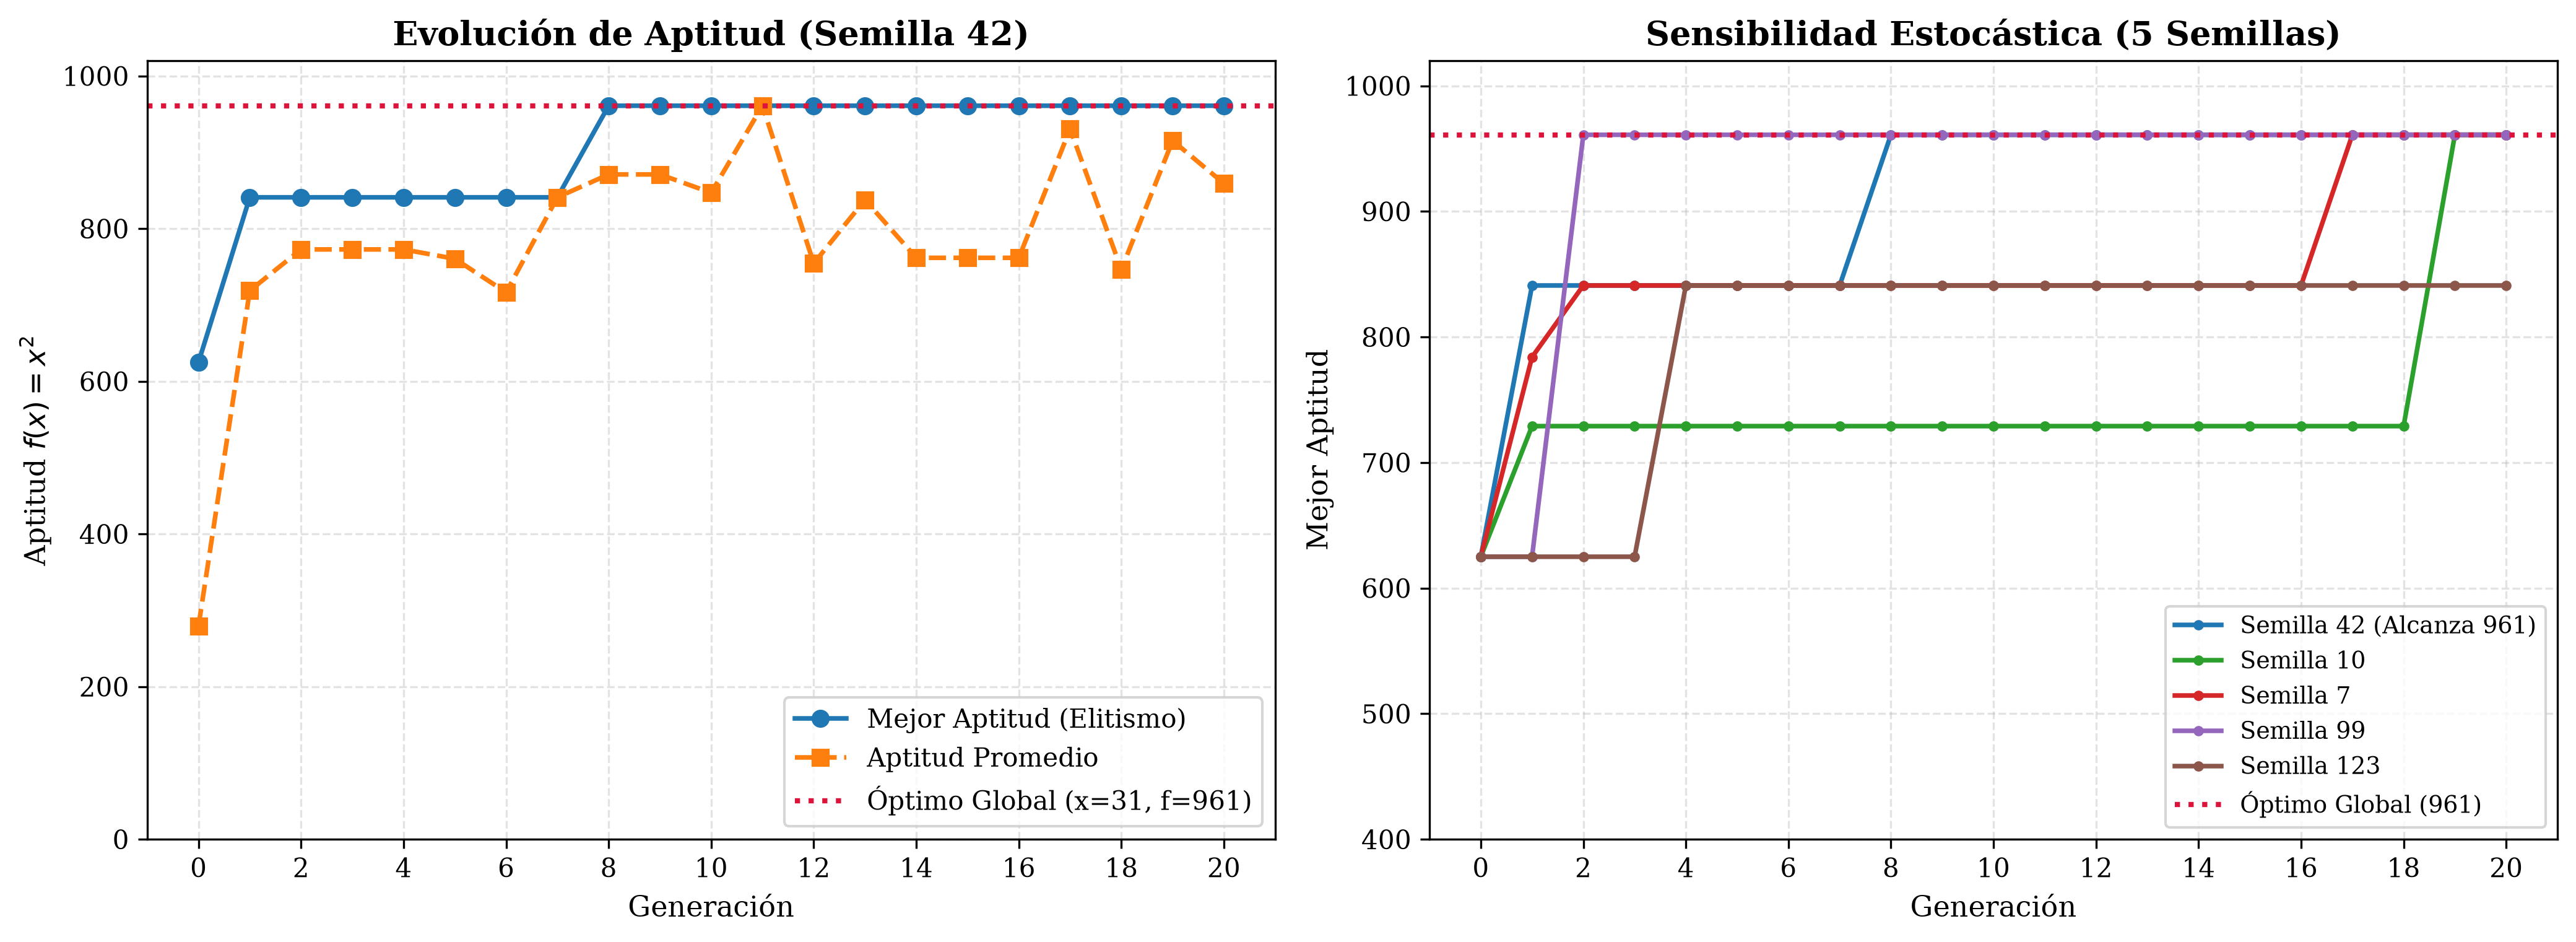

In [3]:
# Gráfica de evolución y análisis de convergencia multiesperimento
gens = [h['gen'] for h in hist_ga]
best_fits = [h['mejor_fit'] for h in hist_ga]
avg_fits = [h['prom_fit'] for h in hist_ga]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# Subgráfico 1: Corrida oficial semilla 42
ax1.plot(gens, best_fits, 'o-', color='#1f77b4', label='Mejor Aptitud (Elitismo)')
ax1.plot(gens, avg_fits, 's--', color='#ff7f0e', label='Aptitud Promedio')
ax1.axhline(961, color='crimson', linestyle=':', linewidth=2, label='Óptimo Global (x=31, f=961)')
ax1.set_title("Evolución de Aptitud (Semilla 42)", fontweight="bold")
ax1.set_xlabel("Generación")
ax1.set_ylabel("Aptitud $f(x) = x^2$")
ax1.set_xticks(range(0, 21, 2))
ax1.set_ylim(0, 1020)
ax1.legend(loc="lower right")
ax1.grid(True)

# Subgráfico 2: Sensibilidad estocástica en 5 corridas independientes
semillas = [42, 10, 7, 99, 123]
colores = ['#1f77b4', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
for s, col in zip(semillas, colores):
    h_s = ejecutar_algoritmo_genetico(seed=s)
    lbl = f"Semilla {s}" + (" (Alcanza 961)" if s == 42 else "")
    ax2.plot(gens, [h['mejor_fit'] for h in h_s], marker='.', color=col, label=lbl)

ax2.axhline(961, color='crimson', linestyle=':', linewidth=2, label='Óptimo Global (961)')
ax2.set_title("Sensibilidad Estocástica (5 Semillas)", fontweight="bold")
ax2.set_xlabel("Generación")
ax2.set_ylabel("Mejor Aptitud")
ax2.set_xticks(range(0, 21, 2))
ax2.set_ylim(400, 1020)
ax2.legend(loc="lower right", fontsize=9)
ax2.grid(True)

plt.tight_layout()
plt.show()


### Pregunta de Interpretación (Punto 1.B)
* **¿El algoritmo encontró el óptimo global?**  
  **Sí.** Con la semilla oficial $42$, el algoritmo alcanzó en la generación 8 el cromosoma `11111`, cuyo valor decimal es $x = 31$, arrojando una aptitud $f(31) = 31^2 = 961$. Este valor coincide exactamente con el máximo global teórico de la función objetivo sobre el dominio acotado $x \in \{0, 1, \dots, 31\}$. Gracias al mecanismo de **elitismo**, la aptitud de 961 se conservó intacta hasta la generación 20.

* **¿Por qué una ejecución de veinte generaciones no garantiza encontrarlo en el caso general?**  
  1. **Naturaleza metaheurística estocástica:** Los algoritmos genéticos operan mediante operadores probabilísticos (ruleta, cruce y mutación). No son algoritmos deterministas ni exhaustivos.
  2. **Población extremadamente reducida ($N=4$):** En una población de solo cuatro cromosomas, el muestreo del espacio de $2^5 = 32$ configuraciones es diminuto. El fenómeno de *deriva genética* causa que alelos particulares colapsen rápidamente. Si en las primeras generaciones la población pierde los bits '1' en ciertas posiciones y converge a un óptimo local (como `11101`, $x=29, f=841$), el cruce entre individuos idénticos jamás producirá un nuevo alelo.
  3. **Tasa de mutación baja ($p_m = 0.05$):** La probabilidad de que un gen específico mute en una generación es del $5\%$. Con solo 4 individuos y 20 generaciones (un total de $4 \times 5 \times 20 = 400$ eventos de bit independientes), la probabilidad conjunta de mutar el bit preciso faltante antes de que la presión selectiva fije la población subóptima es finita y no unitaria, tal como demuestra la gráfica de sensibilidad donde otras semillas se estancan temporalmente.


---
## Punto 2. Ascenso de Colinas y Óptimos Locales (1,0)

Considere el siguiente espacio unidimensional discreto:
$$\begin{array}{c|ccccccccc}
x & 0 & 1 & 2 & 3 & 4 & 5 & 6 & 7 & 8 \\
\hline
f(x) & 1 & 4 & 7 & 5 & 3 & 6 & 9 & 8 & 5
\end{array}$$

Se desea maximizar $f(x)$.  
Los vecinos de $x$ son $x-1$ y $x+1$, siempre que pertenezcan al dominio $[0, 8]$.  
El algoritmo elige el vecino con mayor valor y **solo se mueve si existe una mejora estricta** ($f(\text{vecino}) > f(\text{actual})$).

---

### A. Componente Matemático y Conceptual (0,5)

#### 1. Traza manual desde $x_0 = 0$:
* **Estado $x = 0$ ($f(0) = 1$):** Vecino admisible $x=1$ con $f(1)=4$. Como $4 > 1$, hay mejora estricta. $\to$ Transición a $x = 1$.
* **Estado $x = 1$ ($f(1) = 4$):** Vecinos $x=0$ ($f=1$) y $x=2$ ($f=7$). Mejor vecino: $x=2$ ($f=7$). Como $7 > 4$, hay mejora estricta. $\to$ Transición a $x = 2$.
* **Estado $x = 2$ ($f(2) = 7$):** Vecinos $x=1$ ($f=4$) y $x=3$ ($f=5$). Mejor vecino: $x=3$ ($f=5$). Como $5 \ngtr 7$, no existe mejora estricta.  
  El algoritmo se detiene.
* **Trayectoria:** $0 \to 1 \to 2$.  
* **Estado final:** $x^* = 2$, con valor $f(2) = 7$.

#### 2. Traza manual desde $x_0 = 4$:
* **Estado $x = 4$ ($f(4) = 3$):** Vecinos $x=3$ ($f=5$) y $x=5$ ($f=6$). Mejor vecino: $x=5$ ($f=6$). Como $6 > 3$, hay mejora estricta. $\to$ Transición a $x = 5$.
* **Estado $x = 5$ ($f(5) = 6$):** Vecinos $x=4$ ($f=3$) y $x=6$ ($f=9$). Mejor vecino: $x=6$ ($f=9$). Como $9 > 6$, hay mejora estricta. $\to$ Transición a $x = 6$.
* **Estado $x = 6$ ($f(6) = 9$):** Vecinos $x=5$ ($f=6$) y $x=7$ ($f=8$). Mejor vecino: $x=7$ ($f=8$). Como $8 \ngtr 9$, no existe mejora estricta.  
  El algoritmo se detiene.
* **Trayectoria:** $4 \to 5 \to 6$.  
* **Estado final:** $x^* = 6$, con valor $f(6) = 9$.

#### 3. Identificación de Óptimos
* **Máximos Locales:**  
  * $x = 2$, pues $f(2) = 7 > f(1) = 4$ y $f(2) = 7 > f(3) = 5$.
  * $x = 6$, pues $f(6) = 9 > f(5) = 6$ y $f(6) = 9 > f(7) = 8$.
* **Máximo Global:**  
  * $x = 6$, ya que $f(6) = 9 \ge f(x)$ para todo $x \in \{0, 1, \dots, 8\}$.

#### 4. ¿Por qué cambiar el estado inicial modifica el resultado?
Porque el algoritmo de ascenso de colinas es estrictamente miope y codicioso (*greedy*): solo evalúa mejoras locales inmediatas en la vecindad. El espacio de búsqueda queda particionado en **cuencas de atracción** (*basins of attraction*). Si el estado inicial pertenece a la cuenca de atracción de un pico secundario, el gradiente ascendente conducirá de forma irreversible al óptimo local, pues el algoritmo carece de mecanismos para descender o saltar valles.

#### 5. Estrategia para reducir el riesgo de óptimos locales y costo adicional
* **Estrategia propuesta:** **Ascenso de Colinas con Reinicios Aleatorios (*Random Restart Hill Climbing*)** o **Temple Simulado (*Simulated Annealing*)**.
* **Mecanismo:** En reinicios aleatorios, se ejecutan $k$ búsquedas independientes comenzando desde puntos generados uniformemente al azar en el dominio, conservando al final la mejor solución encontrada entre todas las réplicas.
* **Costo adicional:** El costo computacional escala linealmente con el número de reinicios: si cada ascenso toma en promedio $L$ evaluaciones de la función objetivo, $k$ reinicios consumirán $O(k \cdot L)$ evaluaciones, multiplicando el tiempo de ejecución pero reduciendo exponencialmente la probabilidad de fracaso a $(1 - p)^k$.


In [4]:
# Implementación en Python - Punto 2 (Parte B)
VALORES = [1, 4, 7, 5, 3, 6, 9, 8, 5]

def ascenso_colinas(valores, inicio):
    """Devuelve el estado final y la trayectoria."""
    n = len(valores)
    actual = inicio
    trayectoria = [actual]

    while True:
        vecinos = []
        if actual > 0:
            vecinos.append(actual - 1)
        if actual < n - 1:
            vecinos.append(actual + 1)

        mejor_vecino = max(vecinos, key=lambda v: valores[v])

        if valores[mejor_vecino] > valores[actual]:
            actual = mejor_vecino
            trayectoria.append(actual)
        else:
            break

    return actual, trayectoria

# Ejecución desde todos los estados iniciales posibles (0 a 8)
tabla_resultados = []
conduce_a_global = 0

for x0 in range(len(VALORES)):
    final, tray = ascenso_colinas(VALORES, x0)
    val_final = VALORES[final]
    es_global = (final == 6)
    if es_global:
        conduce_a_global += 1
    tabla_resultados.append({
        "x0": x0,
        "trayectoria": tray,
        "x_final": final,
        "f_final": val_final,
        "tipo": "Máximo Global" if es_global else "Máximo Local"
    })

print("=" * 80)
print("RESULTADOS DE ASCENSO DE COLINAS PARA TODOS LOS ESTADOS INICIALES")
print("=" * 80)
print(f"{'Inicio (x0)':>11} | {'Trayectoria':>22} | {'Estado Final (x*)':>17} | {'f(x*)':>6} | {'Clasificación':>15}")
print("-" * 80)
for r in tabla_resultados:
    tray_str = ' -> '.join(map(str, r['trayectoria']))
    print(f"{r['x0']:11d} | {tray_str:>22} | {r['x_final']:17d} | {r['f_final']:6d} | {r['tipo']:>15}")
print("=" * 80)

proporcion = conduce_a_global / len(VALORES)
print(f"Proporción de estados iniciales que conducen al Máximo Global: {proporcion:.4f} ({conduce_a_global} de {len(VALORES)}, {proporcion*100:.2f}%)")


RESULTADOS DE ASCENSO DE COLINAS PARA TODOS LOS ESTADOS INICIALES
Inicio (x0) |            Trayectoria | Estado Final (x*) |  f(x*) |   Clasificación
--------------------------------------------------------------------------------
          0 |            0 -> 1 -> 2 |                 2 |      7 |    Máximo Local
          1 |                 1 -> 2 |                 2 |      7 |    Máximo Local
          2 |                      2 |                 2 |      7 |    Máximo Local
          3 |                 3 -> 2 |                 2 |      7 |    Máximo Local
          4 |            4 -> 5 -> 6 |                 6 |      9 |   Máximo Global
          5 |                 5 -> 6 |                 6 |      9 |   Máximo Global
          6 |                      6 |                 6 |      9 |   Máximo Global
          7 |                 7 -> 6 |                 6 |      9 |   Máximo Global
          8 |            8 -> 7 -> 6 |                 6 |      9 |   Máximo Global
Proporción de

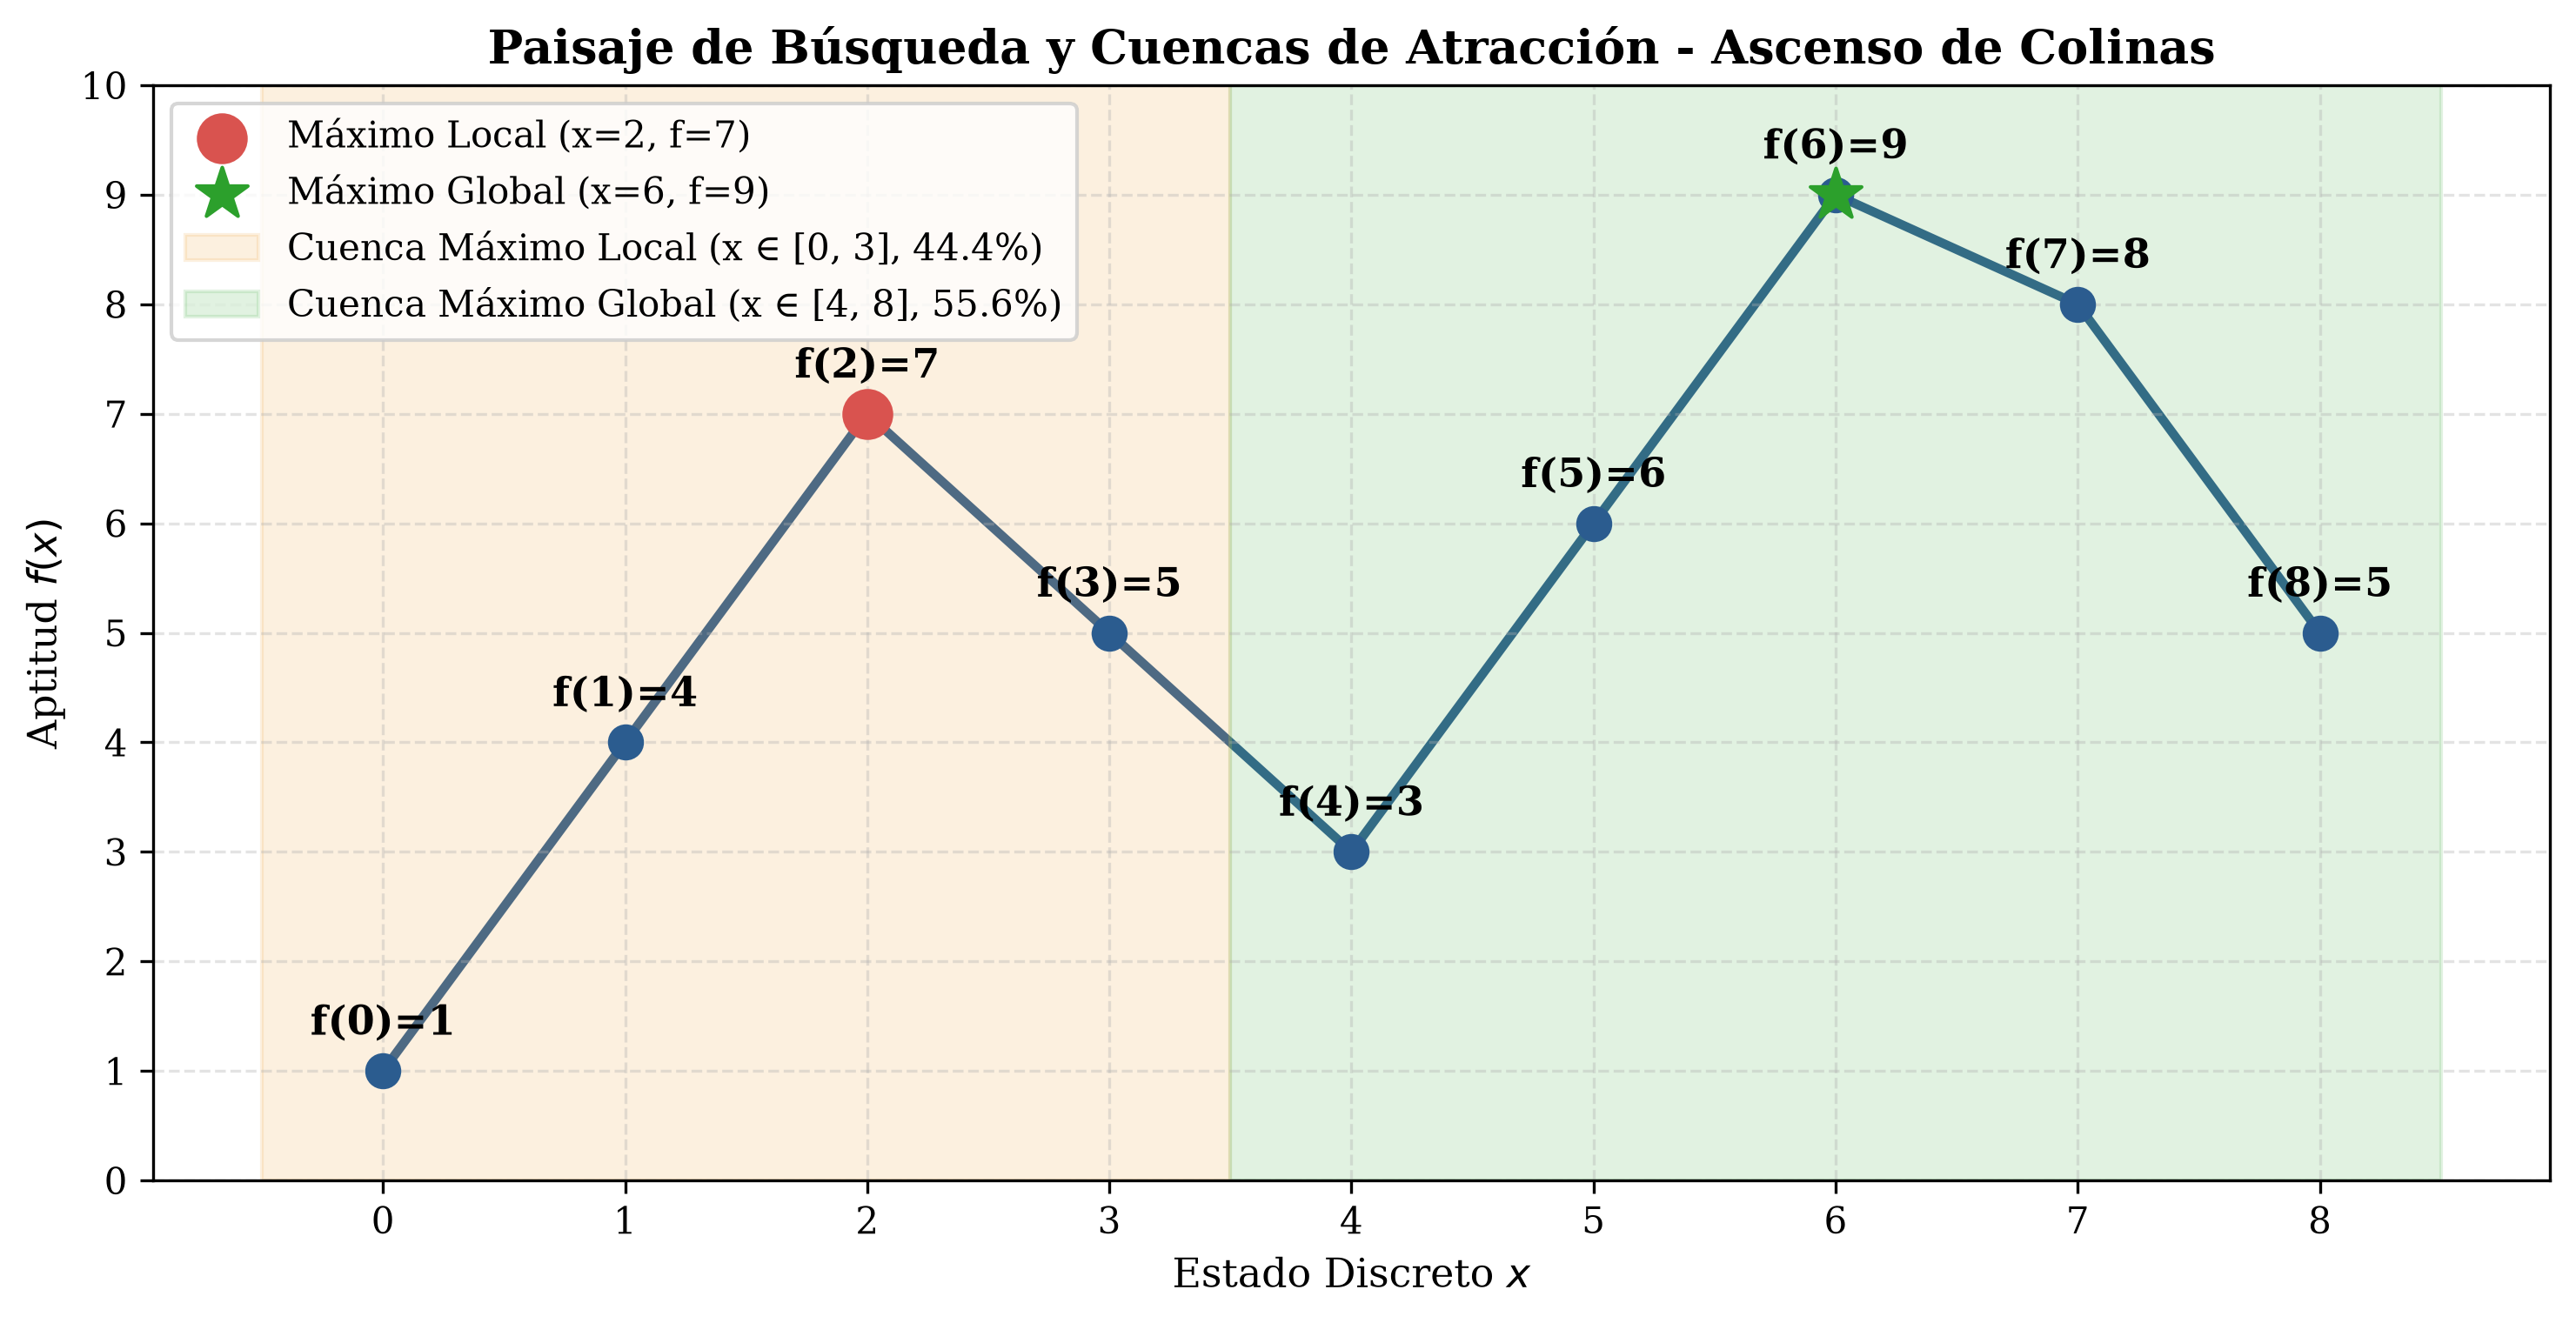

In [5]:
# Visualización del paisaje discreto y cuencas de atracción
x_vals = list(range(len(VALORES)))

plt.figure(figsize=(10, 5.2))
plt.plot(x_vals, VALORES, color="#2b5c8f", linestyle="-", linewidth=2.5, zorder=1)
plt.scatter(x_vals, VALORES, color="#2b5c8f", s=80, zorder=2)

plt.scatter([2], [7], color="#d9534f", s=170, zorder=3, label="Máximo Local (x=2, f=7)")
plt.scatter([6], [9], color="#2ca02c", s=220, zorder=3, marker="*", label="Máximo Global (x=6, f=9)")

for x, val in zip(x_vals, VALORES):
    plt.annotate(f"f({x})={val}", (x, val), textcoords="offset points", xytext=(0, 10), ha="center", fontweight="bold")

plt.axvspan(-0.5, 3.5, color="#f0ad4e", alpha=0.18, label="Cuenca Máximo Local (x ∈ [0, 3], 44.4%)")
plt.axvspan(3.5, 8.5, color="#5cb85c", alpha=0.18, label="Cuenca Máximo Global (x ∈ [4, 8], 55.6%)")

plt.title("Paisaje de Búsqueda y Cuencas de Atracción - Ascenso de Colinas", fontweight="bold")
plt.xlabel("Estado Discreto $x$")
plt.ylabel("Aptitud $f(x)$")
plt.xticks(x_vals)
plt.yticks(range(0, 11))
plt.legend(loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()


### Pregunta de Interpretación (Punto 2.B)
* **¿Qué proporción de los nueve estados iniciales conduce al máximo global?**  
  Exactamente **$5$ de los $9$ estados posibles** conducen al máximo global ($x=6, f=9$), lo que equivale a una proporción de:
  $$\frac{5}{9} \approx 0.5556 \quad (55.56\%)$$
  Los otros 4 estados ($x_0 \in \{0, 1, 2, 3\}$) caen en la cuenca del máximo local ($x=2, f=7$), representando el $44.44\%$.

* **¿Cómo se relaciona este resultado con los reinicios aleatorios?**  
  Cada reinicio aleatorio muestrea de manera independiente un estado inicial uniforme en $\{0, 1, \dots, 8\}$. Por ende, la probabilidad de éxito de una corrida individual es $p = 5/9$.  
  La probabilidad de que **todas** las $k$ corridas independientes fracasen (es decir, caigan en el máximo local) decae exponencialmente:
  $$P(\text{Fracaso en } k \text{ reinicios}) = (1 - p)^k = \left(\frac{4}{9}\right)^k$$
  Así, la probabilidad de encontrar el óptimo global con $k$ reinicios aleatorios es:
  $$P(\text{Éxito con } k \text{ reinicios}) = 1 - \left(\frac{4}{9}\right)^k$$
  * Para $k=1$: $55.56\%$
  * Para $k=2$: $1 - (4/9)^2 = 80.25\%$
  * Para $k=4$: $1 - (4/9)^4 = 96.09\%$
  * Para $k=6$: $1 - (4/9)^6 = 99.23\%$
  
  Esto demuestra rigurosamente por qué los reinicios aleatorios convierten un algoritmo local con riesgo de atasco en una estrategia con garantía asintótica de éxito.


---
## Punto 3. Temple Simulado: Aceptación de Soluciones Peores (1,0)

Se desea minimizar la función de energía:
$$E(x) = x^2, \quad x \in \{-5, -4, \dots, 5\}$$

La regla de aceptación de Metrópolis es:
$$P(\text{aceptar}) = \begin{cases} 
1, & \Delta E \le 0 \\
e^{-\Delta E / T}, & \Delta E > 0 
\end{cases}$$
donde $\Delta E = E(x_{\text{nuevo}}) - E(x_{\text{actual}})$.  
Una solución peor se acepta cuando $u < P(\text{aceptar})$, con $u \sim \mathcal{U}[0, 1)$.

---

### A. Componente Matemático y Conceptual (0,5)

Analizamos cada transición de manera independiente:

#### Caso A: $x_{\text{actual}} = 3$, $x_{\text{candidato}} = 2$, $T = 5$, $u = 0.70$
* $E(x_{\text{actual}}) = 3^2 = 9$
* $E(x_{\text{candidato}}) = 2^2 = 4$
* $\Delta E = 4 - 9 = -5$
* Como $\Delta E = -5 \le 0$, el movimiento representa una mejora estricta del objetivo de minimización.
* Probabilidad de aceptación: $P(\text{aceptar}) = 1.0$
* Comparación con $u$: Como $u = 0.70 < 1.0$, **la decisión es ACEPTAR**.

#### Caso B: $x_{\text{actual}} = 2$, $x_{\text{candidato}} = 3$, $T = 5$, $u = 0.30$
* $E(x_{\text{actual}}) = 2^2 = 4$
* $E(x_{\text{candidato}}) = 3^2 = 9$
* $\Delta E = 9 - 4 = +5 > 0$ (solución peor)
* Probabilidad de aceptación de Metrópolis:
  $$P(\text{aceptar}) = e^{-\Delta E / T} = e^{-5 / 5} = e^{-1} \approx 0.367879$$
* Comparación con $u$: Como $u = 0.30 < 0.367879$, **la decisión es ACEPTAR** (se acepta probabilísticamente una solución degradante).

#### Caso C: $x_{\text{actual}} = 2$, $x_{\text{candidato}} = 3$, $T = 1$, $u = 0.30$
* $E(x_{\text{actual}}) = 4$, $E(x_{\text{candidato}}) = 9 \implies \Delta E = +5 > 0$
* Con temperatura baja $T = 1$:
  $$P(\text{aceptar}) = e^{-\Delta E / T} = e^{-5 / 1} = e^{-5} \approx 0.006738$$
* Comparación con $u$: Como $u = 0.30 \ge 0.006738$, **la decisión es RECHAZAR**.

---

#### 2. ¿Cómo influye la temperatura en la aceptación de soluciones peores?
La temperatura $T$ actúa como un parámetro de control de la entropía o tolerancia al deterioro:
* **Altas temperaturas ($T \to \infty$):** $-\Delta E / T \to 0$, de modo que $e^{-\Delta E / T} \to 1$. El algoritmo acepta prácticamente cualquier solución peor, favoreciendo una exploración de amplio espectro (comportamiento cuasi-caminata aleatoria).
* **Bajas temperaturas ($T \to 0$):** $-\Delta E / T \to -\infty$, por lo que $e^{-\Delta E / T} \to 0$. La probabilidad de aceptar degradaciones se vuelve despreciable, transicionando a una fase de explotación estricta donde solo se admiten mejoras.

#### 3. ¿Qué dificultad puede producir un enfriamiento demasiado rápido?
Produce el fenómeno de **congelamiento prematuro** o *quenched annealing*. Al colapsar la temperatura con excesiva celeridad, el algoritmo pierde la capacidad de superar barreras de energía y queda atrapado irreversiblemente en el primer mínimo local que encuentra, degenerando en un simple descenso de colinas codicioso sin converger al óptimo global.

#### 4. Comparación de la regla de movimiento: Temple Simulado vs Ascenso de Colinas
* **Ascenso/Descenso de Colinas:** Sigue una política determinista y estrictamente monótona: se mueve a un vecino si y solo si $\Delta E < 0$ (en minimización). Es incapaz de escapar de óptimos locales.
* **Temple Simulado:** Incorpora el criterio estocástico de Metrópolis: acepta incondicionalmente mejoras ($\Delta E \le 0$), pero además acepta degradaciones ($\Delta E > 0$) con probabilidad finita $e^{-\Delta E/T}$, permitiendo atravesar valles y escapar de óptimos locales para buscar el mínimo global.


In [6]:
# Implementación en Python - Punto 3 (Parte B)
def temple_simulado(x0=5, T0=10.0, factor=0.90, max_iter=100, seed=42):
    random.seed(seed)
    np.random.seed(seed)

    actual_x = x0
    actual_E = actual_x ** 2

    mejor_x = actual_x
    mejor_E = actual_E

    historial_T = []
    historial_actual_E = []
    historial_mejor_E = []
    historial_actual_x = []

    T = T0

    for k in range(max_iter):
        historial_T.append(T)
        historial_actual_E.append(actual_E)
        historial_mejor_E.append(mejor_E)
        historial_actual_x.append(actual_x)

        # Vecinos admisibles dentro de [-5, 5]
        vecinos = []
        if actual_x > -5:
            vecinos.append(actual_x - 1)
        if actual_x < 5:
            vecinos.append(actual_x + 1)

        candidato_x = random.choice(vecinos)
        candidato_E = candidato_x ** 2
        dE = candidato_E - actual_E

        # Regla de Metrópolis
        if dE <= 0:
            aceptar = True
        else:
            p_aceptar = math.exp(-dE / T)
            u = random.random()
            aceptar = (u < p_aceptar)

        if aceptar:
            actual_x = candidato_x
            actual_E = candidato_E
            if actual_E < mejor_E:
                mejor_x = actual_x
                mejor_E = actual_E

        T = T * factor

    return mejor_x, mejor_E, actual_x, actual_E, historial_T, historial_actual_E, historial_mejor_E, historial_actual_x

mejor_x, mejor_E, final_x, final_E, hist_T, hist_act_E, hist_bst_E, hist_act_x = temple_simulado()

print("=" * 60)
print("RESULTADOS DE TEMPLE SIMULADO (Semilla 42, 100 iteraciones)")
print("=" * 60)
print(f"Estado inicial:             x0 = 5, E(x0) = 25")
print(f"Temperatura inicial:        T0 = 10.0")
print(f"Enfriamiento geométrico:    T_{{k+1}} = 0.90 * T_k")
print(f"Mejor solución encontrada:  x* = {mejor_x}")
print(f"Energía mínima encontrada:  E* = {mejor_E}")
print(f"Estado final en iter 100:   x_final = {final_x}, E = {final_E}")
print(f"Temperatura final:          T_final = {hist_T[-1]:.6f}")
print("=" * 60)


RESULTADOS DE TEMPLE SIMULADO (Semilla 42, 100 iteraciones)
Estado inicial:             x0 = 5, E(x0) = 25
Temperatura inicial:        T0 = 10.0
Enfriamiento geométrico:    T_{k+1} = 0.90 * T_k
Mejor solución encontrada:  x* = 0
Energía mínima encontrada:  E* = 0
Estado final en iter 100:   x_final = 0, E = 0
Temperatura final:          T_final = 0.000295


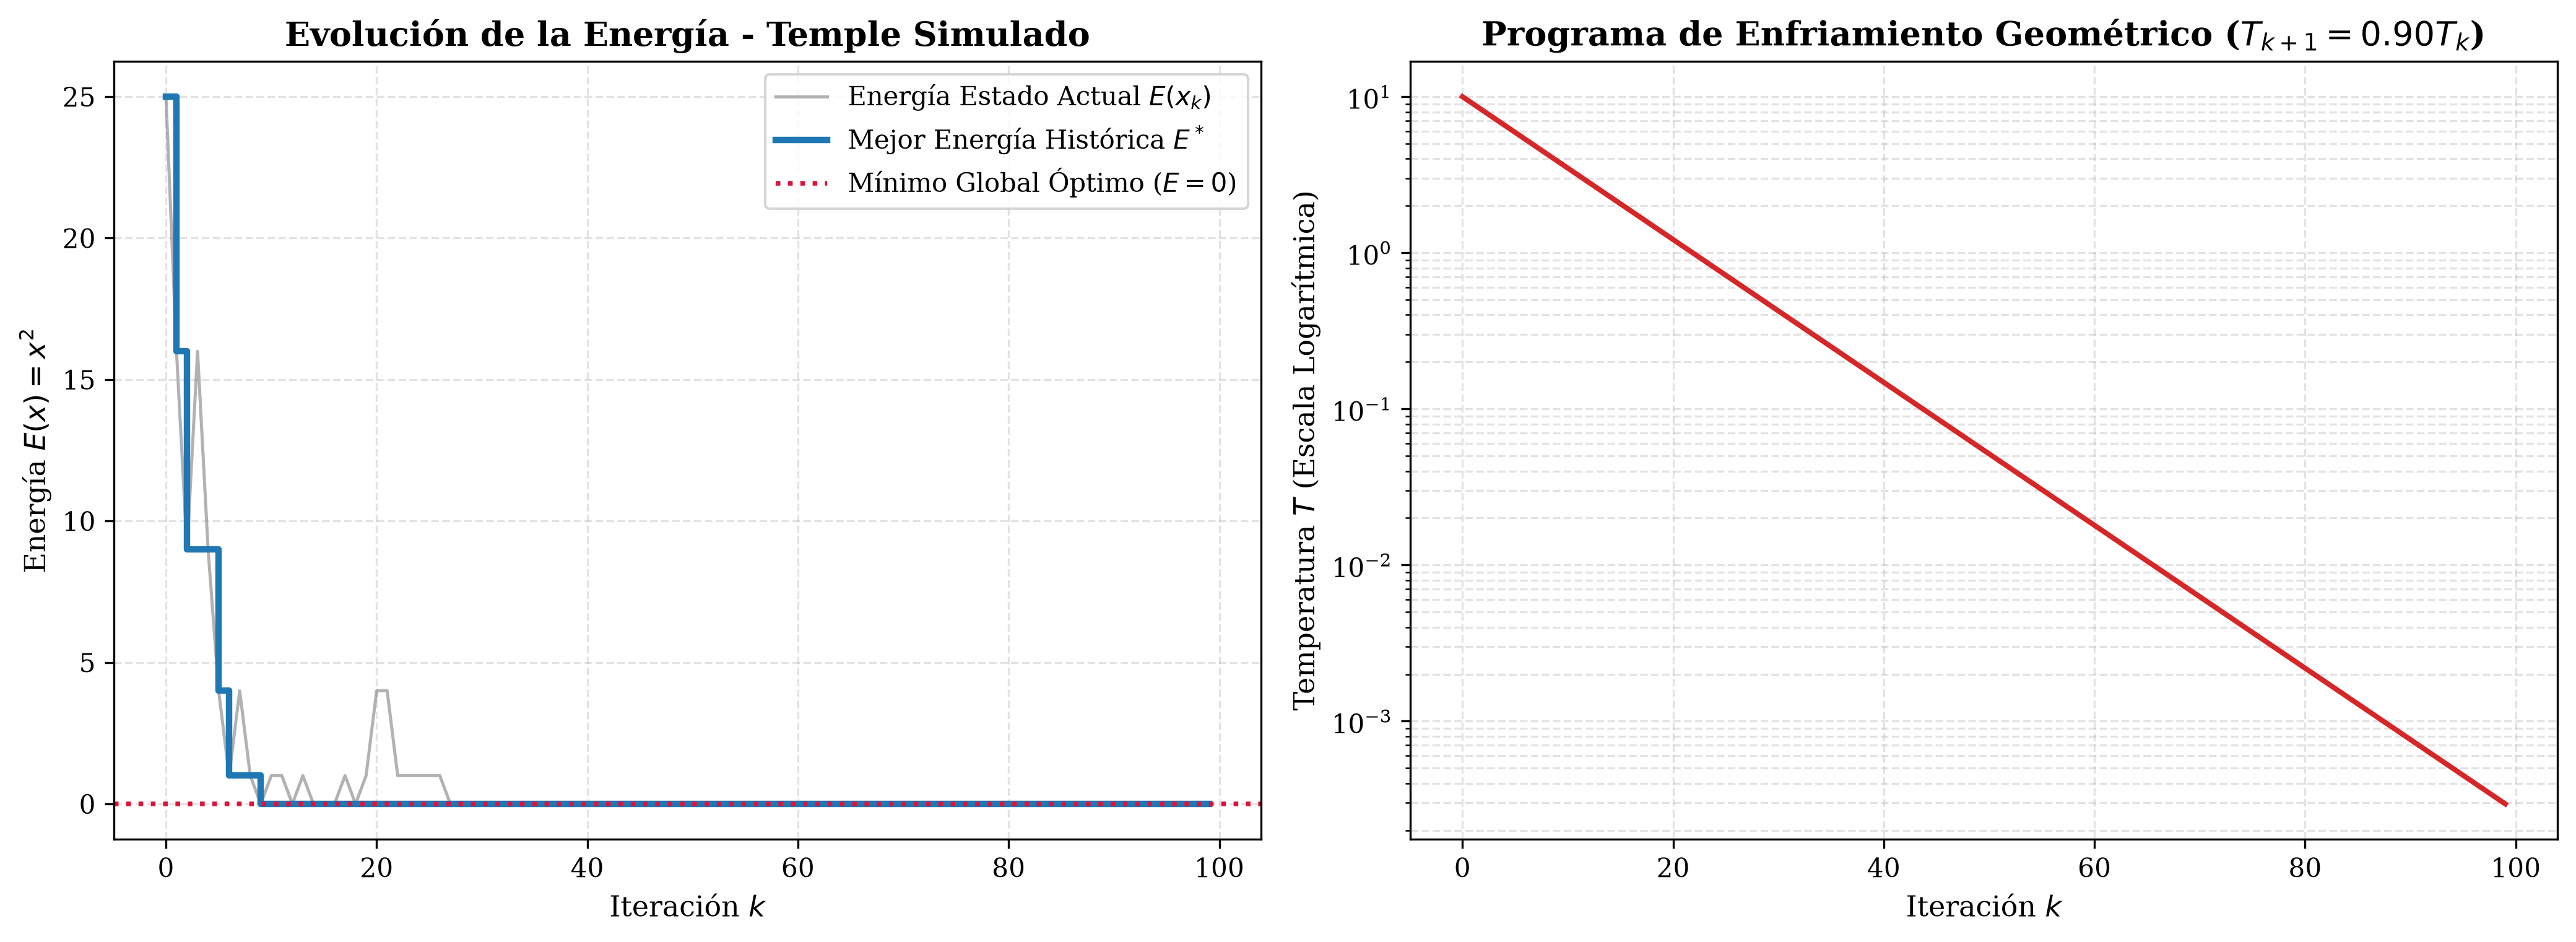

In [7]:
# Gráfica de convergencia de energía y decaimiento térmico
iters = list(range(len(hist_T)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# Subgráfico 1: Dinámica de la energía
ax1.plot(iters, hist_act_E, color="#7f7f7f", alpha=0.6, linewidth=1.2, label="Energía Estado Actual $E(x_k)$")
ax1.step(iters, hist_bst_E, color="#1f77b4", linewidth=2.5, where="post", label="Mejor Energía Histórica $E^*$")
ax1.axhline(0, color="crimson", linestyle=":", linewidth=1.8, label="Mínimo Global Óptimo ($E=0$)")
ax1.set_title("Evolución de la Energía - Temple Simulado", fontweight="bold")
ax1.set_xlabel("Iteración $k$")
ax1.set_ylabel("Energía $E(x) = x^2$")
ax1.legend(loc="upper right")
ax1.grid(True)

# Subgráfico 2: Decaimiento geométrico de temperatura
ax2.plot(iters, hist_T, color="#d62728", linewidth=2.0)
ax2.set_title("Programa de Enfriamiento Geométrico ($T_{k+1} = 0.90 T_k$)", fontweight="bold")
ax2.set_xlabel("Iteración $k$")
ax2.set_ylabel("Temperatura $T$ (Escala Logarítmica)")
ax2.set_yscale("log")
ax2.grid(True, which="both")

plt.tight_layout()
plt.show()


### Pregunta de Interpretación (Punto 3.B)
* **¿Por qué conviene almacenar la mejor solución encontrada, además del estado actual?**  
  Porque el Temple Simulado es una metaheurística estocástica que acepta transiciones no monótonas:
  1. Durante las fases de temperatura alta y media, el estado actual $x_k$ efectúa fluctuaciones deliberadas aceptando soluciones de mayor energía para explorar el dominio y eludir óptimos locales.
  2. Incluso hacia el final de la búsqueda, una perturbación térmica o una caminata aleatoria local puede mover el estado actual $x$ lejos del óptimo que ya había sido visitado.
  3. Si solo se conservara el estado al terminar la iteración final ($x_{100}$), se correría el riesgo de reportar una solución subóptima debido a una fluctuación tardía.  
  
  Mantener la variable histórica `best_so_far` garantiza que el algoritmo **nunca pierda la mejor configuración física o matemática descubierta en toda su trayectoria**.


---
## Punto 4. ACO: Elección de Rutas y Actualización de Feromonas (1,0)

Una hormiga se encuentra en el nodo $A$ y debe elegir su siguiente nodo entre los destinos disponibles $B, C, D$:

$$\begin{array}{c|c|c}
\text{Arista} & \text{Distancia } d_{Aj} & \text{Feromona } \tau_{Aj} \\
\hline
A \to B & 2 & 1 \\
A \to C & 4 & 2 \\
A \to D & 5 & 1
\end{array}$$

Información heurística y regla de transición con $\alpha = 1, \beta = 2$:
$$\eta_{Aj} = \frac{1}{d_{Aj}}, \qquad p_{Aj} = \frac{\tau_{Aj}^\alpha \eta_{Aj}^\beta}{\sum_{k \in \{B, C, D\}} \tau_{Ak}^\alpha \eta_{Ak}^\beta}$$

---

### A. Componente Matemático y Conceptual (0,5)

#### 1. Cálculo de Pesos y Probabilidades:
* **Heurísticas $\eta_{Aj} = 1 / d_{Aj}$:**
  * $\eta_{AB} = 1/2 = 0.50$
  * $\eta_{AC} = 1/4 = 0.25$
  * $\eta_{AD} = 1/5 = 0.20$

* **Pesos $W_{Aj} = \tau_{Aj}^1 \cdot \eta_{Aj}^2$:**
  * $W_{AB} = 1^1 \cdot (0.50)^2 = 1 \cdot 0.25 = 0.2500 = \frac{1}{4}$
  * $W_{AC} = 2^1 \cdot (0.25)^2 = 2 \cdot 0.0625 = 0.1250 = \frac{1}{8}$
  * $W_{AD} = 1^1 \cdot (0.20)^2 = 1 \cdot 0.04 = 0.0400 = \frac{1}{25}$

* **Suma total de pesos:**
  $$\sum_{k} W_{Ak} = 0.25 + 0.125 + 0.04 = 0.4150$$

* **Probabilidades normalizadas $p_{Aj} = W_{Aj} / 0.415$:**
  * $p_{AB} = \frac{0.250}{0.415} = \frac{50}{83} \approx 0.602410 \quad (60.24\%)$
  * $p_{AC} = \frac{0.125}{0.415} = \frac{25}{83} \approx 0.301205 \quad (30.12\%)$
  * $p_{AD} = \frac{0.040}{0.415} = \frac{8}{83} \approx 0.096386 \quad (9.64\%)$
  * **Verificación:** $0.602410 + 0.301205 + 0.096386 = 1.000000$

#### 2. Alternativa más probable y análisis de garantía:
* **Alternativa más probable:** $A \to B$ con $60.24\%$ de probabilidad.
* **¿Su elección está garantizada?**  
  **No.** La toma de decisiones en ACO se basa en una regla de selección estocástica proporcional (ruleta de probabilidades). Existe una probabilidad acumulada del $39.76\%$ ($30.12\% + 9.64\%$) de que la hormiga seleccione los nodos alternativos $C$ o $D$. La estocasticidad es deliberada para garantizar la exploración colectiva del enjambre.

#### 3. Actualización de Feromonas tras una Ruta con $L = 10$ que utiliza $A \to B$:
Regla de actualización con $ho = 0.2$, $Q = 10$, $\Delta \tau_{AB} = Q / L = 10 / 10 = 1.0$, y depósito nulo en las otras aristas:
$$\tau_{Aj}^{\text{nueva}} = (1 - ho) \tau_{Aj} + \Delta \tau_{Aj}$$

* **Arista $A \to B$:**
  $$\tau_{AB}^{\text{nueva}} = (1 - 0.2)(1.0) + 1.0 = 0.8 + 1.0 = 1.8000$$
* **Arista $A \to C$:**
  $$\tau_{AC}^{\text{nueva}} = (1 - 0.2)(2.0) + 0.0 = 1.6000$$
* **Arista $A \to D$:**
  $$\tau_{AD}^{\text{nueva}} = (1 - 0.2)(1.0) + 0.0 = 0.8000$$

#### 4. Función de la evaporación y dominancia excesiva de feromonas
* **Función de la evaporación ($ho$):** Actúa como un mecanismo de olvido de la memoria colectiva. Al desgastar continuamente los rastros de feromona en las aristas, evita que decisiones tempranas subóptimas se vuelvan permanentes y libera al enjambre para explorar nuevas alternativas.
* **Dominancia excesiva de feromona:** Si la feromona dominara de forma desmedida (por ejemplo, si $\alpha \gg \beta$ o $ho \to 0$), el primer camino completado comenzaría a atraer rápidamente a todas las hormigas subsiguientes por retroalimentación positiva descontrolada, provocando **convergencia prematura y estancamiento** en soluciones de mala calidad.


In [8]:
# Implementación en Python - Punto 4 (Parte B)
def simular_aco_rutas(seed=42):
    random.seed(seed)
    np.random.seed(seed)

    rutas = ["A-B-Z", "A-C-Z", "A-D-Z"]
    longitudes = {"A-B-Z": 6.0, "A-C-Z": 8.0, "A-D-Z": 10.0}
    tau = {r: 1.0 for r in rutas}

    alpha = 1.0
    beta = 2.0
    rho = 0.2
    Q = 10.0
    num_hormigas = 10
    num_iteraciones = 20

    frecuencias = {r: 0 for r in rutas}
    historial_tau = {r: [] for r in rutas}
    historial_prob = {r: [] for r in rutas}

    for it in range(num_iteraciones):
        # 1. Probabilidades usando feromonas actuales
        pesos = {r: (tau[r] ** alpha) * ((1.0 / longitudes[r]) ** beta) for r in rutas}
        sum_p = sum(pesos.values())
        probs = {r: pesos[r] / sum_p for r in rutas}

        for r in rutas:
            historial_tau[r].append(tau[r])
            historial_prob[r].append(probs[r])

        # 2. Las diez hormigas eligen rutas
        prob_vals = [probs[r] for r in rutas]
        elecciones = random.choices(rutas, weights=prob_vals, k=num_hormigas)

        conteos_iter = {r: elecciones.count(r) for r in rutas}
        for r in rutas:
            frecuencias[r] += conteos_iter[r]

        # 3. Evaporar feromona
        for r in rutas:
            tau[r] = (1.0 - rho) * tau[r]

        # 4. Depósito de feromona
        for r in rutas:
            tau[r] += conteos_iter[r] * (Q / longitudes[r])

    mejor_ruta = min(rutas, key=lambda r: longitudes[r])
    return frecuencias, tau, mejor_ruta, historial_tau, historial_prob, longitudes

frecuencias, final_tau, mejor_ruta, hist_tau, hist_prob, longitudes = simular_aco_rutas(seed=42)

print("=" * 65)
print("RESULTADOS DE ACO - ELECCIÓN DE RUTAS (Semilla 42, 20 iteraciones)")
print("=" * 65)
print("Frecuencias Acumuladas de Elección (Total 200 decisiones):")
for r in frecuencias:
    print(f"  Ruta {r} (L={longitudes[r]:.0f}): {frecuencias[r]:3d} elecciones ({frecuencias[r]/200*100:.1f}%)")

print("\nFeromonas Finales tras 20 iteraciones:")
for r in final_tau:
    print(f"  Ruta {r}: tau = {final_tau[r]:8.4f}")

print(f"\nMejor ruta observada: {mejor_ruta} (Longitud mínima = {longitudes[mejor_ruta]:.0f})")
print("=" * 65)


RESULTADOS DE ACO - ELECCIÓN DE RUTAS (Semilla 42, 20 iteraciones)
Frecuencias Acumuladas de Elección (Total 200 decisiones):
  Ruta A-B-Z (L=6): 187 elecciones (93.5%)
  Ruta A-C-Z (L=8):  12 elecciones (6.0%)
  Ruta A-D-Z (L=10):   1 elecciones (0.5%)

Feromonas Finales tras 20 iteraciones:
  Ruta A-B-Z: tau =  79.2315
  Ruta A-C-Z: tau =   2.3580
  Ruta A-D-Z: tau =   0.0259

Mejor ruta observada: A-B-Z (Longitud mínima = 6)


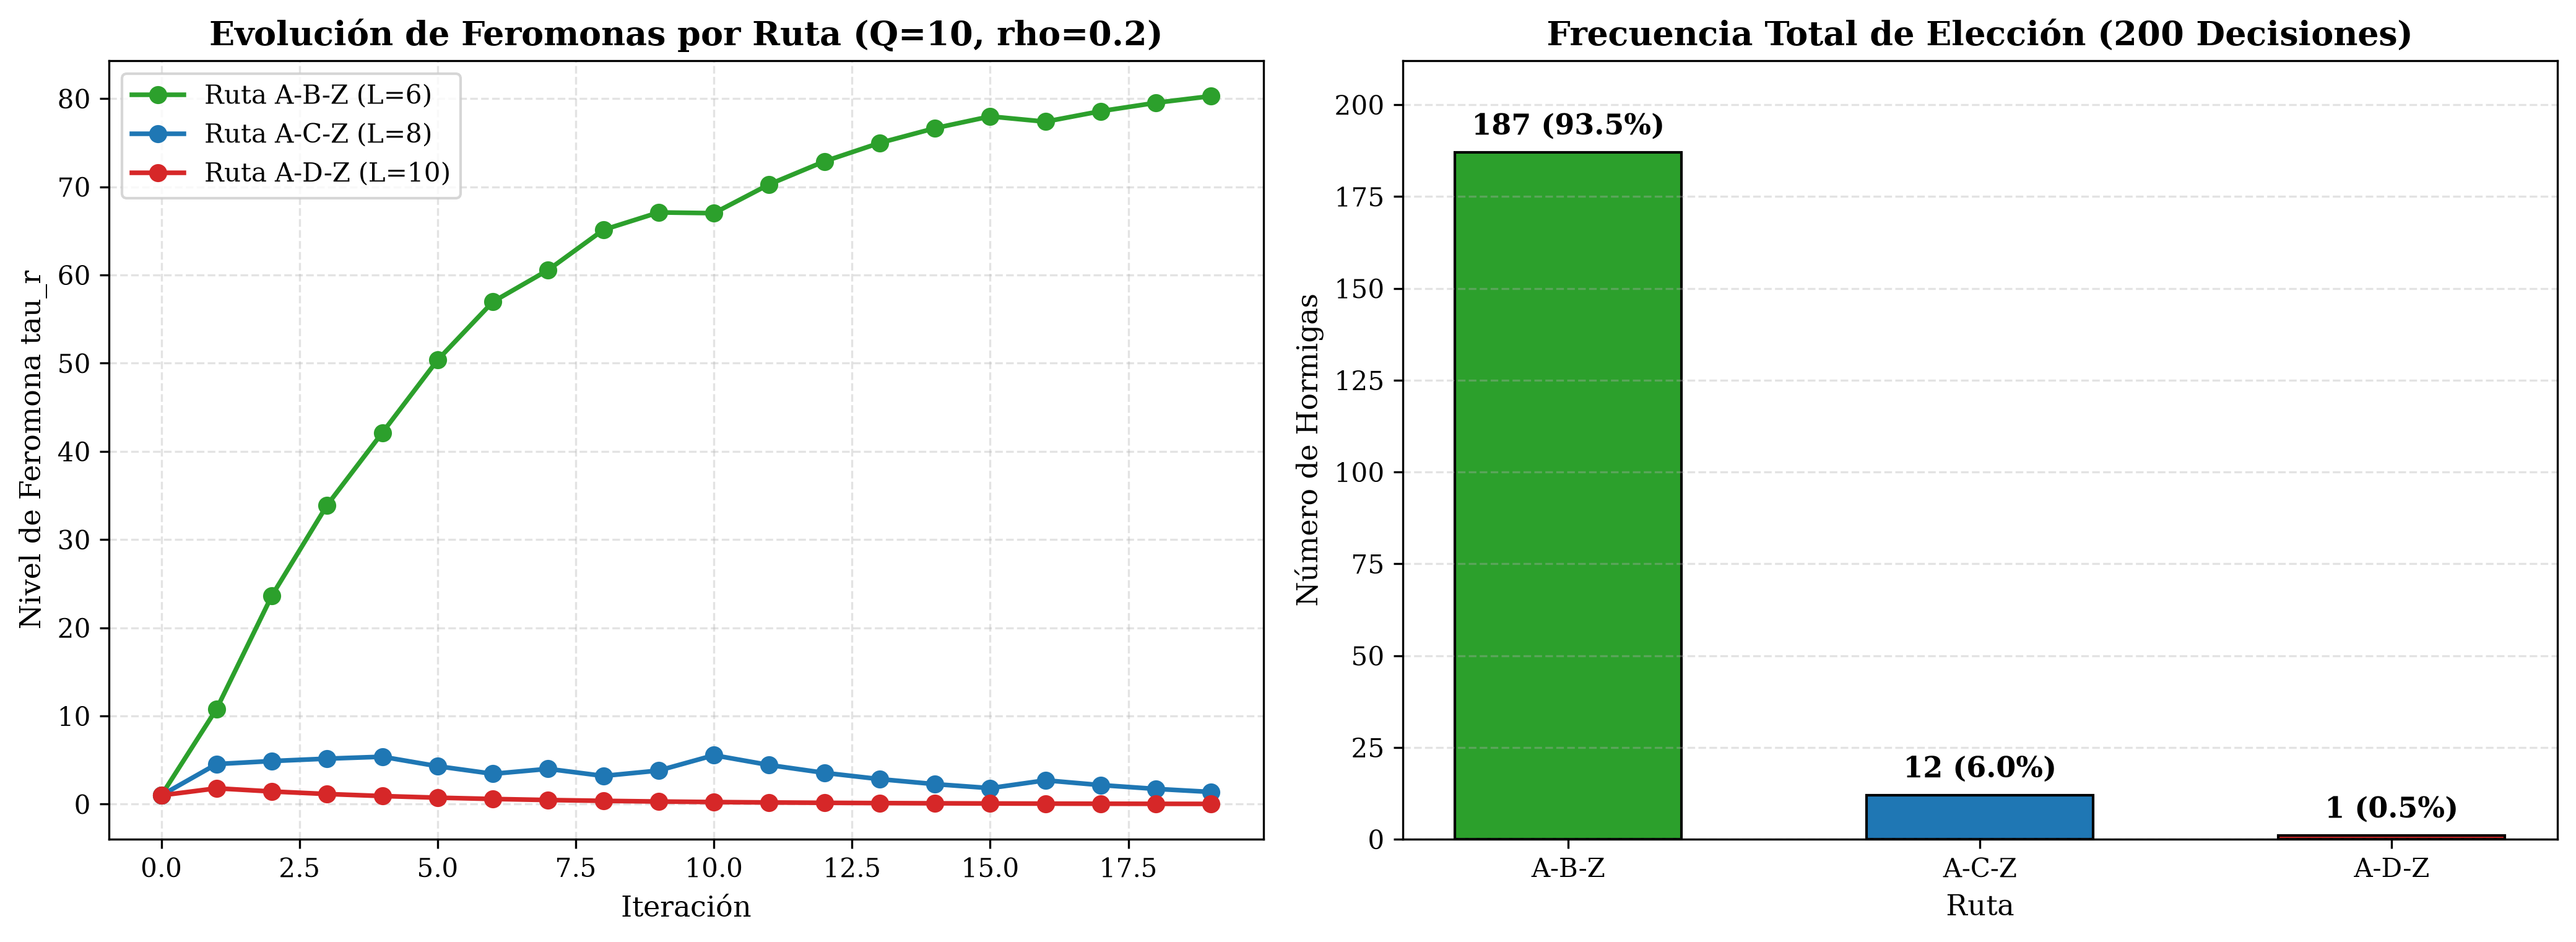

In [9]:
# Gráfica de evolución de feromonas y distribución de elecciones
iters = list(range(20))
rutas = ["A-B-Z", "A-C-Z", "A-D-Z"]
colores = {"A-B-Z": "#2ca02c", "A-C-Z": "#1f77b4", "A-D-Z": "#d62728"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# Subgráfico 1: Evolución temporal de feromonas
for r in rutas:
    ax1.plot(iters, hist_tau[r], "o-", color=colores[r], label=f"Ruta {r} (L={int(longitudes[r])})")
ax1.set_title("Evolución de Feromonas por Ruta (Q=10, rho=0.2)", fontweight="bold")
ax1.set_xlabel("Iteración")
ax1.set_ylabel("Nivel de Feromona tau_r")
ax1.legend(loc="upper left")
ax1.grid(True)

# Subgráfico 2: Frecuencias de elección
counts = [frecuencias[r] for r in rutas]
porcentajes = [c / sum(counts) * 100 for c in counts]
barras = ax2.bar(rutas, counts, color=[colores[r] for r in rutas], edgecolor="black", width=0.55)
for barra, pct in zip(barras, porcentajes):
    yval = barra.get_height()
    ax2.text(barra.get_x() + barra.get_width() / 2.0, yval + 3, f"{yval} ({pct:.1f}%)", ha="center", va="bottom", fontweight="bold")

ax2.set_title("Frecuencia Total de Elección (200 Decisiones)", fontweight="bold")
ax2.set_xlabel("Ruta")
ax2.set_ylabel("Número de Hormigas")
ax2.set_ylim(0, max(counts) + 25)
ax2.grid(True, axis="y")

plt.tight_layout()
plt.show()


### Pregunta de Interpretación (Punto 4.B)
* **¿Cómo la calidad de las rutas y la experiencia colectiva influyen en las elecciones posteriores?**  
  En el algoritmo ACO opera un mecanismo sinérgico dual compuesto por **información heurística a priori** y **memoria estigmérgica a posteriori**:
  1. **Influencia de la calidad intrínseca ($L_r$):** La ruta más corta ($A-B-Z$, con $L_1 = 6$) posee la mayor visibilidad heurística $\eta_r = 1/L_r = 0.1667$. Además, la cantidad de feromona depositada por hormiga es inversamente proporcional a la longitud ($\Delta \tau = Q / L_r = 10/6 = 1.667$, frente a $10/10 = 1.0$ en la ruta más larga).
  2. **Influencia de la experiencia colectiva (retroalimentación positiva / estigmergia):** Como las hormigas se sienten más atraídas hacia $A-B-Z$ desde el inicio, un mayor número de individuos transita por ella en cada ciclo. Al pasar más hormigas, se deposita una masa acumulada de feromona mucho mayor, contrarrestando con holgura la tasa de evaporación $ho = 0.2$.  
  3. **Efecto multiplicativo:** La feromona acumulada refuerza aún más la probabilidad de que las hormigas de la siguiente iteración elijan dicha ruta, mientras que las rutas largas ($A-D-Z$), al recibir escasos depósitos, sufren una evaporación neta progresiva. Esto explica por qué $A-B-Z$ capturó el $93.5\%$ de todas las decisiones del enjambre.


---
## Punto 5. PSO: Movimiento de Partículas y Memoria (1,0)

Se desea minimizar la función $f(x) = x^2$.  
Una partícula se encuentra en el estado:
$$x = 4, \quad v = -1, \quad p_{\text{best}} = 2, \quad g_{\text{best}} = 1$$

Ecuaciones de actualización:
$$v_{\text{nuevo}} = w v + c_1 r_1 (p_{\text{best}} - x) + c_2 r_2 (g_{\text{best}} - x)$$
$$x_{\text{nuevo}} = x + v_{\text{nuevo}}$$

Parámetros dados:
$$w = 0.5, \quad c_1 = 1.5, \quad c_2 = 1.5, \quad r_1 = 0.4, \quad r_2 = 0.6$$

---

### A. Componente Matemático y Conceptual (0,5)

#### 1. Cálculo por separado de los componentes de velocidad:
* **Término de Inercia:**
  $$\text{Inercia} = w \cdot v = 0.5 \cdot (-1) = -0.50$$
* **Término Cognitivo (Memoria Personal):**
  $$\text{Cognitivo} = c_1 \cdot r_1 \cdot (p_{\text{best}} - x) = 1.5 \cdot 0.4 \cdot (2 - 4) = 0.6 \cdot (-2) = -1.20$$
* **Término Social (Memoria Colectiva):**
  $$\text{Social} = c_2 \cdot r_2 \cdot (g_{\text{best}} - x) = 1.5 \cdot 0.6 \cdot (1 - 4) = 0.9 \cdot (-3) = -2.70$$

#### 2. Cálculo de la Nueva Velocidad, Nueva Posición y Aptitud:
* **Nueva velocidad:**
  $$v_{\text{nuevo}} = -0.50 + (-1.20) + (-2.70) = -4.40$$
* **Nueva posición:**
  $$x_{\text{nuevo}} = x + v_{\text{nuevo}} = 4 + (-4.40) = -0.40$$
* **Nueva aptitud:**
  $$f(x_{\text{nuevo}}) = (-0.40)^2 = 0.1600$$

#### 3. Determinación de Actualización de Memorias ($p_{\text{best}}$ y $g_{\text{best}}$):
* **Actualización de $p_{\text{best}}$:**  
  La aptitud anterior era $f(p_{\text{best}}) = 2^2 = 4.0$.  
  Como $f(x_{\text{nuevo}}) = 0.16 < 4.0$, **SÍ se actualiza $p_{\text{best}}$**, adoptando el nuevo valor $p_{\text{best}} = -0.40$ (con aptitud $0.16$).
* **Actualización de $g_{\text{best}}$:**  
  La aptitud anterior era $f(g_{\text{best}}) = 1^2 = 1.0$.  
  Como $f(x_{\text{nuevo}}) = 0.16 < 1.0$ (y asumiendo que las demás partículas no han mejorado), **SÍ se actualiza $g_{\text{best}}$**, adoptando el nuevo valor $g_{\text{best}} = -0.40$ (con aptitud $0.16$).

#### 4. Diferencia entre la Mejor Posición Personal y la Mejor Posición Global:
* **Mejor Posición Personal ($p_{\text{best}}$):** Registra el punto de óptima aptitud visitado individualmente por esa partícula concreta a lo largo de su propia trayectoria histórica. Representa la experiencia cognitiva individual.
* **Mejor Posición Global ($g_{\text{best}}$):** Registra el punto de óptima aptitud visitado por cualquier partícula de todo el enjambre hasta ese momento. Representa el conocimiento social compartido que atrae a todos los miembros hacia la mejor región conocida.

#### 5. Comparación del intercambio de información en PSO vs ACO:
* **En PSO (Comunicación Directa / Topológica):** Las partículas se comunican de forma instantánea a través del broadcast o consulta directa de una variable compartida en memoria ($g_{\text{best}}$). La influencia es vectorial y continua, modificando directamente las aceleraciones espaciales.
* **En ACO (Comunicación Indirecta / Estigmergia):** Las hormigas no se comunican entre sí directamente; se comunican modificando el entorno mediante el depósito físico y evaporación de feromonas. Es una interacción asíncrona, desacoplada espacial y temporalmente, donde la experiencia colectiva se codifica en el propio paisaje de búsqueda.


In [10]:
# Implementación en Python - Punto 5 (Parte B)
def ejecutar_pso_bidimensional(seed=42):
    np.random.seed(seed)

    num_particulas = 10
    dim = 2
    num_iter = 30
    w = 0.5
    c1 = 1.5
    c2 = 1.5
    limites = (-5.0, 5.0)

    # Inicialización de posiciones y velocidades
    X = np.random.uniform(limites[0], limites[1], (num_particulas, dim))
    V = np.zeros((num_particulas, dim))

    def f_objetivo(pos):
        return np.sum(pos ** 2, axis=-1)

    pbest_X = np.copy(X)
    pbest_fitness = f_objetivo(pbest_X)

    mejor_idx = int(np.argmin(pbest_fitness))
    gbest_X = np.copy(pbest_X[mejor_idx])
    gbest_fitness = float(pbest_fitness[mejor_idx])

    historial_gbest_fitness = [gbest_fitness]
    historial_particulas_pos = [X.copy()]

    for it in range(1, num_iter + 1):
        # r1, r2 independientes por partícula, dimensión e iteración
        r1 = np.random.uniform(0.0, 1.0, (num_particulas, dim))
        r2 = np.random.uniform(0.0, 1.0, (num_particulas, dim))

        # Actualización usando el mismo gbest para toda la iteración (sincrónico)
        V_nuevo = w * V + c1 * r1 * (pbest_X - X) + c2 * r2 * (gbest_X - X)
        X_nuevo = X + V_nuevo

        # Manejo de límites: ajustar al límite y poner v=0 si excede
        for i in range(num_particulas):
            for d in range(dim):
                if X_nuevo[i, d] < limites[0]:
                    X_nuevo[i, d] = limites[0]
                    V_nuevo[i, d] = 0.0
                elif X_nuevo[i, d] > limites[1]:
                    X_nuevo[i, d] = limites[1]
                    V_nuevo[i, d] = 0.0

        X = X_nuevo
        V = V_nuevo

        # Evaluación y actualización de memorias
        current_fit = f_objetivo(X)
        for i in range(num_particulas):
            if current_fit[i] < pbest_fitness[i]:
                pbest_fitness[i] = current_fit[i]
                pbest_X[i] = np.copy(X[i])

        iter_best_idx = int(np.argmin(pbest_fitness))
        if pbest_fitness[iter_best_idx] < gbest_fitness:
            gbest_fitness = float(pbest_fitness[iter_best_idx])
            gbest_X = np.copy(pbest_X[iter_best_idx])

        historial_gbest_fitness.append(gbest_fitness)
        historial_particulas_pos.append(X.copy())

    return gbest_X, gbest_fitness, historial_gbest_fitness, historial_particulas_pos

gbest_X, gbest_fitness, hist_gbest_fit, hist_parts_pos = ejecutar_pso_bidimensional(seed=42)

print("=" * 65)
print("RESULTADOS DE PSO 2D (Semilla 42, 10 partículas, 30 iteraciones)")
print("=" * 65)
print(f"Mejor posición final g_best: ({gbest_X[0]:.8f}, {gbest_X[1]:.8f})")
print(f"Valor óptimo de la función:  f(g_best) = {gbest_fitness:.10e}")
print("\nHistorial de Aptitud Global:")
for it in [0, 1, 2, 5, 10, 15, 20, 25, 30]:
    print(f"  Iteración {it:2d}: f(g_best) = {hist_gbest_fit[it]:.8e}")
print("=" * 65)


RESULTADOS DE PSO 2D (Semilla 42, 10 partículas, 30 iteraciones)
Mejor posición final g_best: (-0.00012280, 0.00004545)
Valor óptimo de la función:  f(g_best) = 1.7144507605e-08

Historial de Aptitud Global:
  Iteración  0: f(g_best) = 3.89339803e+00
  Iteración  1: f(g_best) = 6.74402517e-01
  Iteración  2: f(g_best) = 6.74402517e-01
  Iteración  5: f(g_best) = 1.83494517e-02
  Iteración 10: f(g_best) = 4.76094150e-04
  Iteración 15: f(g_best) = 8.07150255e-05
  Iteración 20: f(g_best) = 3.97152316e-06
  Iteración 25: f(g_best) = 5.90418429e-07
  Iteración 30: f(g_best) = 1.71445076e-08


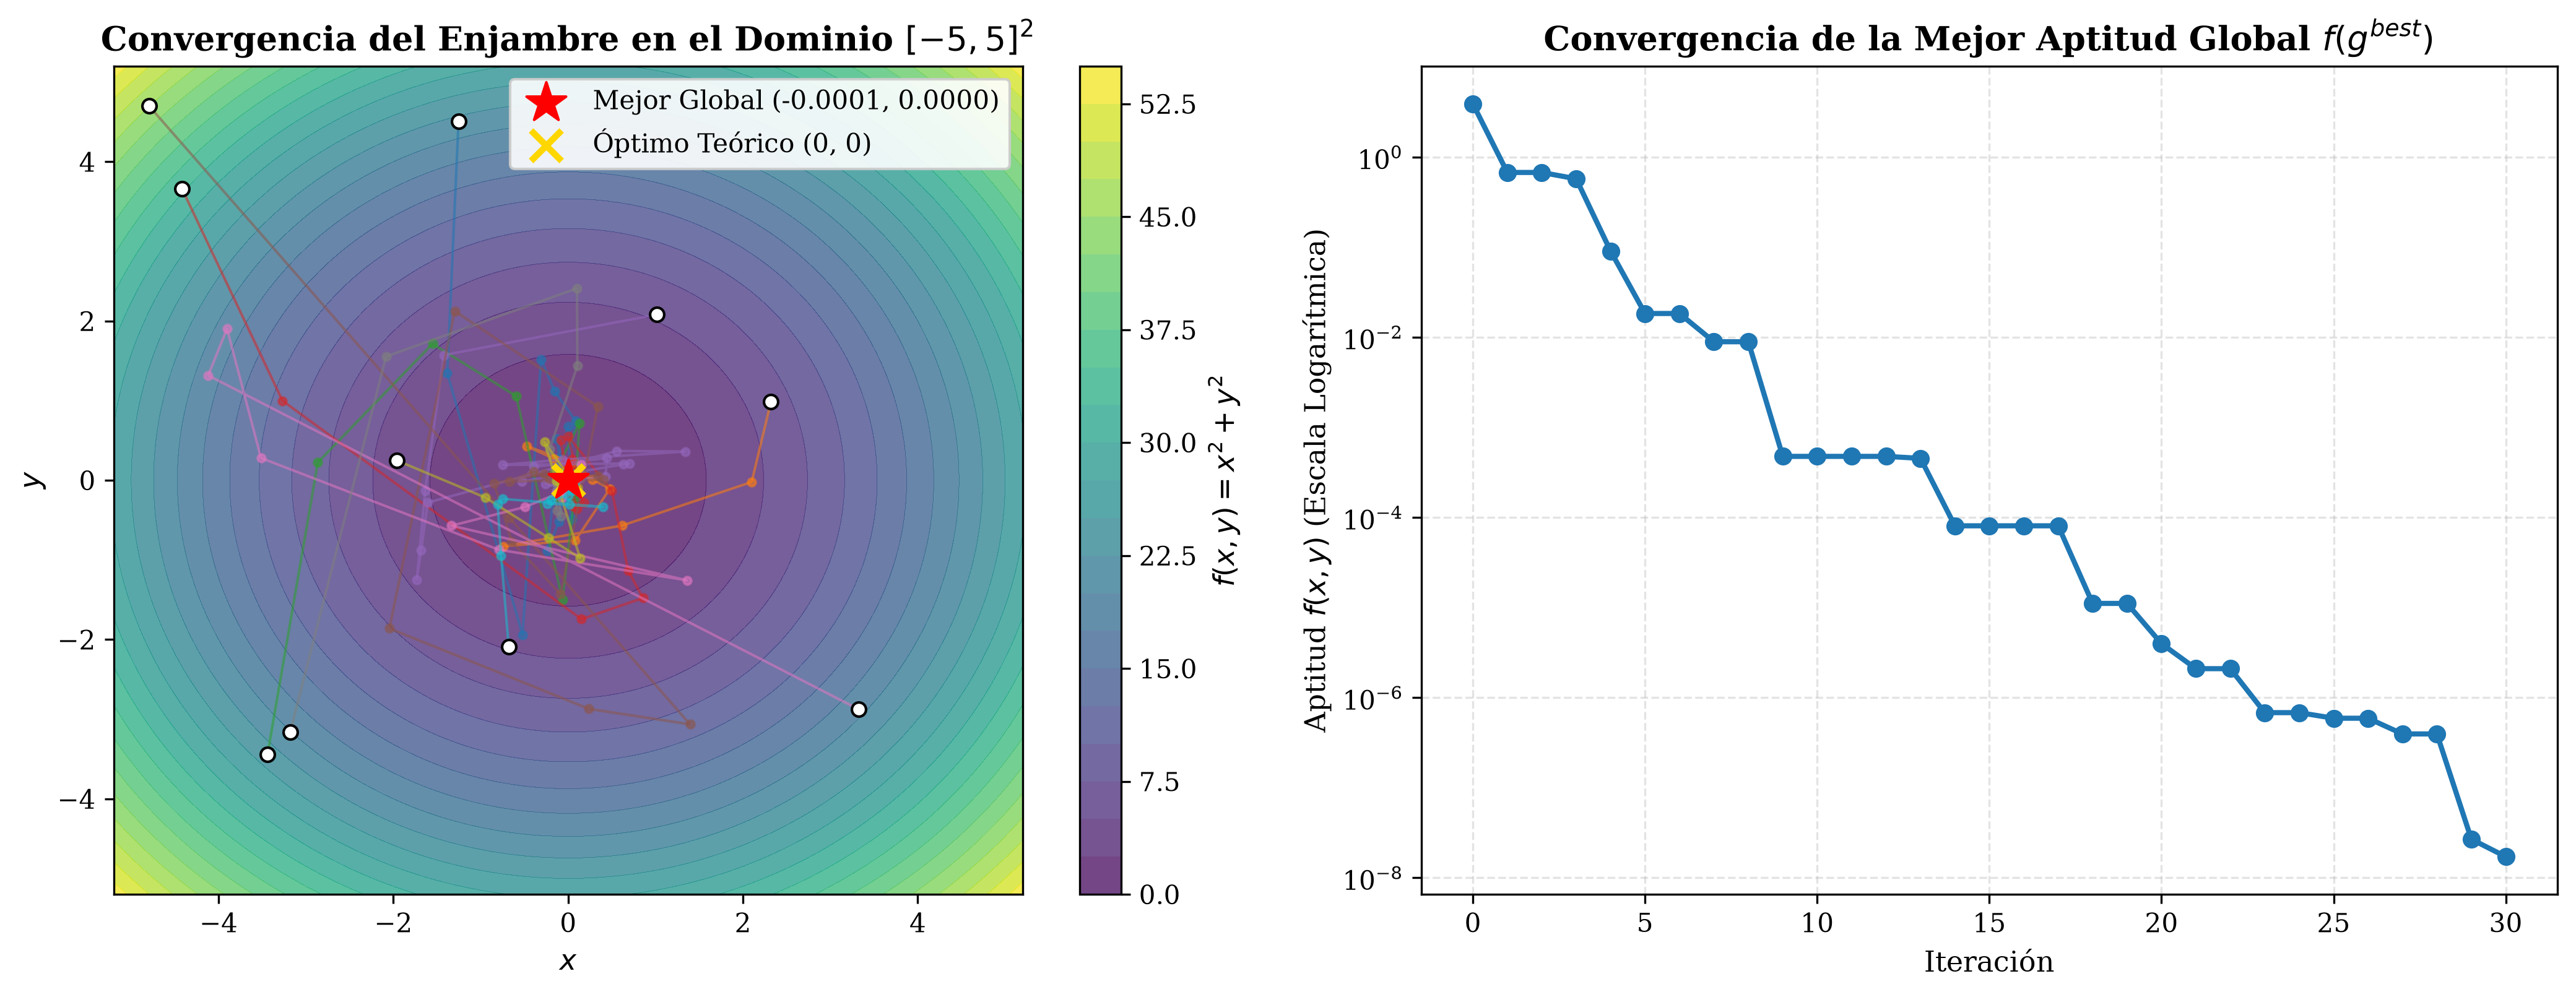

In [11]:
# Visualización de trayectorias en 2D y curva de convergencia
hist_pos = np.array(hist_parts_pos)
iters = list(range(len(hist_gbest_fit)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Subgráfico 1: Curvas de nivel y trayectorias
grid_x = np.linspace(-5.2, 5.2, 200)
grid_y = np.linspace(-5.2, 5.2, 200)
X_grid, Y_grid = np.meshgrid(grid_x, grid_y)
Z_grid = X_grid ** 2 + Y_grid ** 2

cp = ax1.contourf(X_grid, Y_grid, Z_grid, levels=25, cmap="viridis", alpha=0.75)
fig.colorbar(cp, ax=ax1, label="$f(x, y) = x^2 + y^2$")

num_parts = hist_pos.shape[1]
for p in range(num_parts):
    ax1.plot(hist_pos[:, p, 0], hist_pos[:, p, 1], ".-", alpha=0.55, linewidth=1.0)
    ax1.scatter(hist_pos[0, p, 0], hist_pos[0, p, 1], color="white", edgecolor="black", s=30, zorder=3)

ax1.scatter(gbest_X[0], gbest_X[1], color="red", marker="*", s=260, zorder=5, label=f"Mejor Global ({gbest_X[0]:.4f}, {gbest_X[1]:.4f})")
ax1.scatter(0, 0, color="gold", marker="x", s=140, linewidths=2.5, zorder=4, label="Óptimo Teórico (0, 0)")
ax1.set_title("Convergencia del Enjambre en el Dominio $[-5, 5]^2$", fontweight="bold")
ax1.set_xlabel("$x$")
ax1.set_ylabel("$y$")
ax1.set_xlim(-5.2, 5.2)
ax1.set_ylim(-5.2, 5.2)
ax1.legend(loc="upper right", framealpha=0.9)

# Subgráfico 2: Convergencia de aptitud
ax2.plot(iters, hist_gbest_fit, "o-", color="#1f77b4", linewidth=2.0)
ax2.set_title("Convergencia de la Mejor Aptitud Global $f(g^{best})$", fontweight="bold")
ax2.set_xlabel("Iteración")
ax2.set_ylabel("Aptitud $f(x, y)$ (Escala Logarítmica)")
ax2.set_yscale("log")
ax2.grid(True, which="both")

plt.tight_layout()
plt.show()


### Pregunta de Interpretación (Punto 5.B)
* **¿Por qué las partículas pueden converger sin alcanzar exactamente $(0, 0)$?**  
  Las partículas convergen hacia una vecindad infinitesimalmente próxima al origen (en nuestra ejecución alcanzaron $g_{\text{best}} = (-0.00012280, 0.00004545)$ con $f \approx 1.71 \times 10^{-8}$), pero no tocan con precisión analítica el punto $(0, 0)$ por las siguientes razones fundamentales:
  1. **Dominio continuo y discretización temporal:** El espacio de búsqueda es el continuo $\mathbb{R}^2$, donde la probabilidad de que una actualización estocástica caiga exactamente sobre un punto singular de medida cero es teóricamente nula ($P = 0$).
  2. **Inercia y velocidad residual:** La ecuación de velocidad incluye el término de inercia $w = 0.5$ y los coeficientes estocásticos $r_1, r_2 \sim \mathcal{U}[0, 1)$. Aunque las partículas son fuertemente atraídas hacia el centro, siempre conservan una pequeña velocidad residual que las hace oscilar u orbitar microscópicamente en torno al mínimo en lugar de congelarse en reposo estático.
  3. **Número finito de iteraciones ($T=30$):** Con $w = 0.5$, la velocidad decae de forma geométrica. La contracción del radio de oscilación es asintótica; en 30 iteraciones se alcanza una precisión del orden de $10^{-8}$, pero se requerirían infinitas iteraciones para que la velocidad converja estrictamente a cero absoluto.
